[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/16_pca.ipynb)

# 16 · Principal Component Analysis: The Best Low-Dimensional Shadow

**Part 2 — Classical unsupervised learning** · Notebook 16 of 27

Real datasets have many features, and many of them say the same thing twice. Bedrooms and bathrooms rise together. Neighboring pixels in an image are nearly equal. Interest rates for 5 and 7 years move in lockstep. **Principal component analysis** (PCA) finds the few directions along which the data actually varies, and re-describes every point by its coordinates along those directions.

It is the single most used tool for dimensionality reduction: to visualize high-dimensional data in 2-D, to compress images, to remove noise, to decorrelate features before a model, and as the first thing you run on a new dataset. Under the hood it's an eigenvalue problem, which is why notebook 01 spent so long on eigenvectors and the SVD.

**What you'll learn**

1. Why correlated features cause trouble
2. The idea: find the direction with the widest shadow
3. The derivation: variance → covariance → the eigen equation
4. More components, explained variance, and the scree plot
5. PCA from scratch, and why everyone computes it with the **SVD**
6. Preprocessing: centering, scaling, differencing
7. Visualization: 64-dimensional digits on a page
8. Compression and reconstruction
9. **Eigenfaces**, and recognizing faces by their distance from "face space"
10. Denoising
11. PCA on time series: level, slope, curvature
12. **Probabilistic PCA**: PCA as a latent-variable model
13. What PCA can't do

*Course map: ISYE 4600 W3 (Principal Component Analysis: correlated features, projection, variance maximization, eigendecomposition, PCA algorithm, preprocessing, eigenfaces, time series, SVD) and HW2 Q1–Q4 (PCA derivation, covariance matrix, correlated features, PCA on a real table, eigenfaces with projection residuals); CX 4240 lecture 18 (dimension reduction, probabilistic PCA as a Gaussian latent-variable model, three views of PCA, eigenfaces).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.decomposition import PCA, KernelPCA
from sklearn.datasets import load_digits, load_wine, make_circles, make_swiss_roll
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
from skimage import data as skdata
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Why correlated features cause trouble

ISYE's motivating example: predicting rent from number of bedrooms and number of bathrooms. The two features are strongly correlated, and in the extreme case $x_1 = 1.5\,x_2$ for every apartment, they carry **one** piece of information, not two.

In a linear model $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2$, the normal equations need $X^\top X$ (or, in ISYE's row convention, $XX^\top$) to be invertible. With perfectly correlated features, one column is a multiple of another, so it isn't. Here is HW2's numerical check, with ten homes' bathroom counts:

In [2]:
baths = np.array([1, 2, 2, 3, 1, 2, 3, 2, 1, 2], float)
beds = 1.5 * baths                                             # perfectly correlated: x1 = 1.5 x2
Xrows = np.vstack([np.ones(10), beds, baths])                  # ISYE convention: 3 × m, one column per home
G = Xrows @ Xrows.T / 10
print("G = (1/m) X Xᵀ =\n", G.round(3))
print("rank(G) =", np.linalg.matrix_rank(G), "  eigenvalues:", np.linalg.eigvalsh(G).round(4))

G = (1/m) X Xᵀ =
 [[1.    2.85  1.9  ]
 [2.85  9.225 6.15 ]
 [1.9   6.15  4.1  ]]
rank(G) = 2   eigenvalues: [-0.     0.112 14.213]


$G$ is $3\times3$ but has rank 2: one eigenvalue is exactly zero, and its eigenvector, proportional to $(0, 1, -1.5)$, is the combination $x_1 - 1.5x_2$ that is **always zero**. Any multiple of it can be added to $(\beta_1, \beta_2)$ without changing the predictions, so the coefficients aren't identifiable. Real features are rarely *perfectly* correlated, but nearly-correlated ones give nearly-zero eigenvalues, and the coefficients become wildly unstable (we saw this in notebook 05's collinearity demo and fixed it with ridge in notebook 07).

PCA's answer is different: instead of penalizing the coefficients, **replace the correlated features by their dominant combination**. ISYE asks: is "0.5 × bedrooms + 0.5 × bathrooms" the right combination? Which features should be combined, with what weights? PCA answers all of it from the data.

---
## 2. The idea: find the direction with the widest shadow

ISYE's second example: six students' hours studied and exam scores.

| Student | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| Hours | 2.5 | 5.1 | 3.2 | 4.5 | 1.9 | 6.0 |
| Score | 65 | 85 | 70 | 82 | 59 | 92 |

How do we best summarize this data with a single line? Imagine a light shining perpendicular to a line through the data's center: each point casts a **shadow** onto the line (its projection). PCA rotates the line until the shadows are **as spread out as possible**. 🎚️ **Rotate the line** and watch two numbers: the variance of the shadows, and the squared distance from each point to its shadow.

In [3]:
stud = np.array([[2.5, 65], [5.1, 85], [3.2, 70], [4.5, 82], [1.9, 59], [6.0, 92]])
names = list("ABCDEF")
# Put both features on comparable scales for the picture: hours (x10) so the geometry is visible
S_ = stud * np.array([10, 1.0]); mu_s = S_.mean(0); Sc = S_ - mu_s

def best_angle(Xc):
    vals, vecs = np.linalg.eigh(Xc.T @ Xc / len(Xc)); u = vecs[:, -1]; return np.degrees(np.arctan2(u[1], u[0])) % 180

angles = np.linspace(0, 180, 361)
var_at = [np.var(Sc @ np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])) for a in angles]
err_at = [((Sc ** 2).sum(1) - (Sc @ np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])) ** 2).mean() for a in angles]

def shadow(angle=10.0):
    u = np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle))])
    z = Sc @ u; P = np.outer(z, u)                             # scores and projected points
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    ax = axes[0]
    ax.plot(*np.c_[-45 * u, 45 * u], color=C["red"], lw=2)
    for p, q in zip(Sc, P): ax.plot(*np.c_[p, q], color=C["muted"], lw=1, ls=":")
    ax.scatter(*Sc.T, s=70, color=C["blue"], zorder=3); ax.scatter(*P.T, s=50, color=C["red"], marker="s", zorder=4)
    for (xx, yy), n in zip(Sc, names): ax.annotate(n, (xx, yy), xytext=(5, 5), textcoords="offset points")
    ax.set(aspect="equal", xlim=(-30, 30), ylim=(-25, 25), xlabel="hours studied × 10 (centered)", ylabel="exam score (centered)",
           title=f"line at {angle:.0f}°: shadow variance {np.var(z):.1f}, mean squared distance {((Sc - P) ** 2).sum(1).mean():.1f}")
    ax = axes[1]
    ax.plot(angles, var_at, color=C["red"], label="variance of the shadows (maximize)")
    ax.plot(angles, err_at, color=C["blue"], label="mean squared distance to the line (minimize)")
    ax.axvline(angle, color=C["ink"], lw=1); ax.axvline(best_angle(Sc), color=C["aqua"], ls="--", label=f"PCA direction ({best_angle(Sc):.1f}°)")
    ax.set(xlabel="angle of the line (degrees)", title="the two curves always add up to the same total"); ax.legend(fontsize=9, loc="center right")
    fig.tight_layout(); plt.show()

interact(shadow, angle=FloatSlider(value=10, min=0, max=180, step=1, description="angle"));

Two things to notice.

1. **Maximum shadow variance and minimum squared distance happen at the same angle.** For each point, Pythagoras says $\|x\|^2 = (\text{shadow length})^2 + (\text{distance to line})^2$. The left side doesn't depend on the line, so making the shadows spread out as much as possible *is* the same as making the points as close to the line as possible. These are the "max variance" and "min reconstruction error" views of PCA (CX lecture 18).
2. The best line is **not** the regression line. Regression minimizes *vertical* distances (errors in $y$ only), treating hours as fixed. PCA minimizes *perpendicular* distances and treats both features symmetrically. There's no "target" in PCA.

(We multiplied hours by 10 so the picture isn't squashed. That choice matters: section 6 shows that PCA's answer depends on the units.)

---
## 3. The derivation: variance → covariance → eigenvectors

Take $m$ points $x^1, \dots, x^m \in \mathbb{R}^n$ with mean $\mu$. A direction is a unit vector $u$ ($\|u\| = 1$, since only orientation matters). Each point's **score** along $u$ is $u^\top x^i$, the signed length of its shadow. We want the scores to have maximal variance (ISYE W3):

$$\max_{\|u\|=1}\; \frac{1}{m}\sum_{i=1}^m \big(u^\top x^i - u^\top\mu\big)^2.$$

Pull $u$ out of the sum:

$$\frac{1}{m}\sum_i \big(u^\top(x^i - \mu)\big)^2 = \frac1m\sum_i u^\top(x^i-\mu)(x^i-\mu)^\top u = u^\top\Big(\frac1m\sum_i (x^i-\mu)(x^i-\mu)^\top\Big)u = u^\top\Sigma u,$$

where $\Sigma$ is the **covariance matrix**. So the variance along any direction is the quadratic form $u^\top\Sigma u$. To maximize it subject to $u^\top u = 1$, use a Lagrange multiplier (notebook 03):

$$\mathcal{L}(u, \lambda) = u^\top\Sigma u - \lambda(u^\top u - 1), \qquad \nabla_u\mathcal{L} = 2\Sigma u - 2\lambda u = 0 \;\;\Longrightarrow\;\; \Sigma u = \lambda u.$$

The optimal direction must be an **eigenvector** of $\Sigma$. Which one? Plug any unit eigenvector back in: the variance is $u^\top\Sigma u = u^\top\lambda u = \lambda$. So the variance along an eigenvector *is* its eigenvalue, and the maximum is the eigenvector with the **largest eigenvalue**. That's the first principal component (HW2 Q1).

Let's check on the student data, in its original units (ISYE works this example by hand):

In [4]:
mu = stud.mean(0); Xc = stud - mu
Sigma = Xc.T @ Xc / len(Xc)
vals, vecs = np.linalg.eigh(Sigma)                             # eigh: for symmetric matrices, eigenvalues ascending
print("covariance matrix Σ =\n", Sigma.round(2))
print("\neigenvalues:", vals.round(4))
print("eigenvectors (columns):\n", vecs.round(4))
u1 = vecs[:, -1] * np.sign(vecs[1, -1])
print(f"\nPC1 direction u₁ = {u1.round(4)}:  variance along it = u₁ᵀΣu₁ = {u1 @ Sigma @ u1:.2f} = λ₁")
print("scores z = u₁ᵀ(x − μ):", {n: round(float(v), 2) for n, v in zip(names, Xc @ u1)})

covariance matrix Σ =
 [[  2.11  16.92]
 [ 16.92 136.25]]

eigenvalues: [8.400000e-03 1.383505e+02]
eigenvectors (columns):
 [[-0.9924  0.1232]
 [ 0.1232  0.9924]]

PC1 direction u₁ = [0.1232 0.9924]:  variance along it = u₁ᵀΣu₁ = 138.35 = λ₁
scores z = u₁ᵀ(x − μ): {'A': -10.59, 'B': 9.58, 'C': -5.54, 'D': 6.53, 'E': -16.62, 'F': 16.64}


The covariance matrix is dominated by the exam score's variance (136, versus 2.1 for hours), so PC1 points almost entirely along the score axis, with a small positive weight on hours: about 0.12·hours + 0.99·score. Its eigenvalue, 138.35, is 99.9% of the total variance, so one number per student (their score along PC1) describes them almost completely. The scores rank students exactly as their exam marks do, since the two features rise together.

> 🤔 **Question: Why is the eigenvector the "direction that doesn't rotate"?** (ISYE W3)
>
> $\Sigma$ is a linear map. Most vectors get both stretched and turned when you apply it, but an eigenvector only gets stretched: $\Sigma u = \lambda u$. For a covariance matrix, the stretched-only directions are exactly the axes of the data's ellipse-shaped cloud, and the stretch factor is the variance along that axis. Notebook 01's animation of a matrix acting on the unit circle shows the same picture.

---
## 4. More components, explained variance, and the scree plot

After PC1, the **second** principal component is the direction of maximal variance that is **orthogonal** to the first:

$$u_2 = \arg\max_{u}\; u^\top\Sigma u \quad\text{s.t. } \|u\| = 1,\; u^\top u_1 = 0.$$

The same Lagrange argument (with a second multiplier for the orthogonality constraint) shows $u_2$ is the eigenvector with the second-largest eigenvalue, and so on. Because $\Sigma$ is symmetric, its eigenvectors are orthonormal, so this all fits together: $\Sigma = U\Lambda U^\top$ with $U = [u_1, \dots, u_n]$ and $\Lambda = \mathrm{diag}(\lambda_1 \ge \dots \ge \lambda_n \ge 0)$.

Two consequences worth seeing:

- **The scores are uncorrelated.** The new coordinates $z = U^\top(x - \mu)$ have covariance $U^\top\Sigma U = \Lambda$, which is diagonal. PCA turns correlated features into uncorrelated ones.
- **Variance is redistributed, not created.** The total variance $\sum_j \Sigma_{jj} = \mathrm{trace}(\Sigma) = \sum_j\lambda_j$. The fraction $\lambda_k/\sum_j\lambda_j$ is the **explained variance ratio** of component $k$.

In 3-D, with data that mostly lives near a tilted plane:

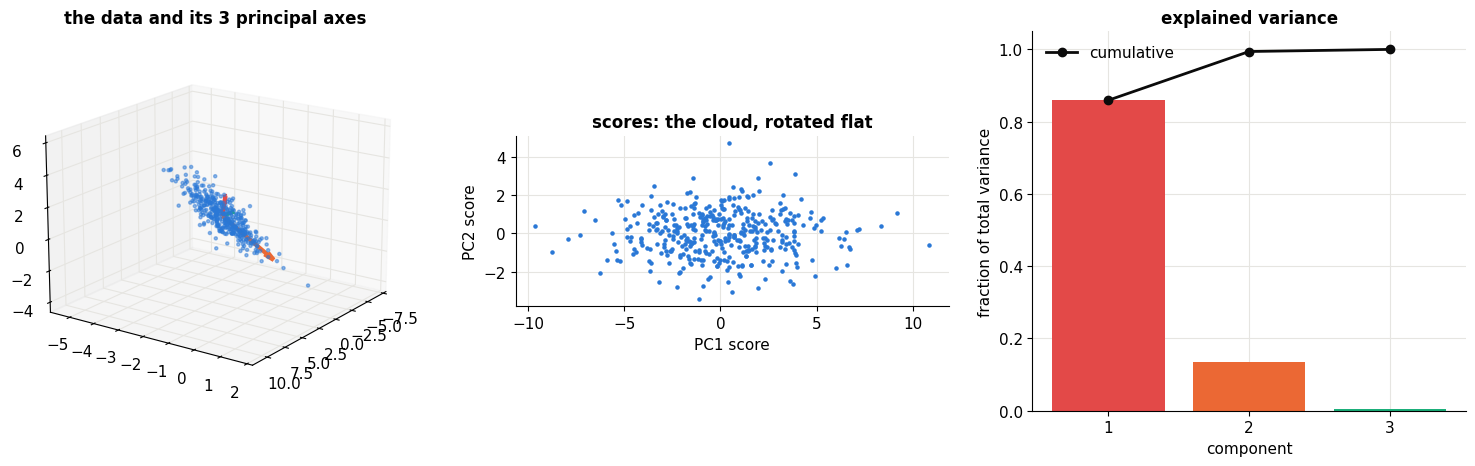

correlation of the PC scores:
 [[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]


In [5]:
r_ = np.random.default_rng(0)
Z3 = r_.normal(size=(400, 3)) * np.array([3.0, 1.2, 0.25])     # wide, medium, thin
Q, _ = np.linalg.qr(r_.normal(size=(3, 3)))                    # a random rotation
X3 = Z3 @ Q.T + np.array([1, -2, 0.5])
pca3 = PCA(3).fit(X3)
fig = plt.figure(figsize=(15, 4.8))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter(*X3.T, s=5, color=C["blue"], alpha=0.5)
for k, col in zip(range(3), [C["red"], C["orange"], C["aqua"]]):
    v = pca3.components_[k] * 2.5 * np.sqrt(pca3.explained_variance_[k])
    ax.quiver(*pca3.mean_, *v, color=col, lw=3, arrow_length_ratio=0.15)
ax.set(title="the data and its 3 principal axes"); ax.view_init(18, 35)
Zs = pca3.transform(X3)
ax = fig.add_subplot(1, 3, 2); ax.scatter(Zs[:, 0], Zs[:, 1], s=5, color=C["blue"]); ax.set(aspect="equal", xlabel="PC1 score", ylabel="PC2 score", title="scores: the cloud, rotated flat")
ax = fig.add_subplot(1, 3, 3)
ax.bar([1, 2, 3], pca3.explained_variance_ratio_, color=[C["red"], C["orange"], C["aqua"]])
ax.plot([1, 2, 3], np.cumsum(pca3.explained_variance_ratio_), "o-", color=C["ink"], label="cumulative")
ax.set(xticks=[1, 2, 3], xlabel="component", ylabel="fraction of total variance", title="explained variance"); ax.legend()
fig.tight_layout(); plt.show()
print("correlation of the PC scores:\n", np.corrcoef(Zs.T).round(4))

Two components hold about 99% of the variance: the third direction (aqua) is the thin dimension of the plane. The score correlations are zero off the diagonal.

A plot of the eigenvalues in decreasing order is a **scree plot** (named after the rubble at the foot of a cliff). Its elbow is a common way to choose how many components to keep. On the 64-pixel digits:

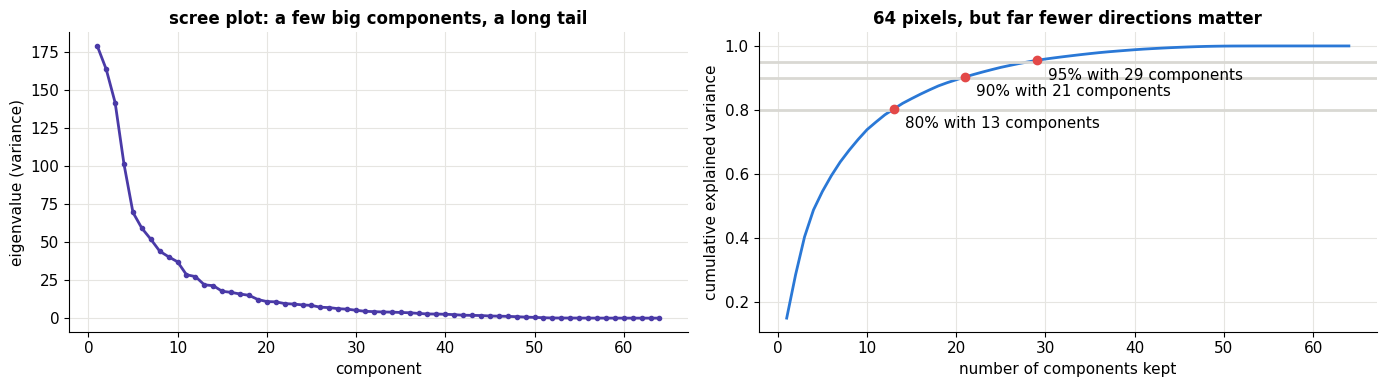

In [6]:
digits = load_digits(); Xd, yd = digits.data, digits.target
pd_full = PCA().fit(Xd)
cum = np.cumsum(pd_full.explained_variance_ratio_)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 65), pd_full.explained_variance_, "o-", ms=3, color=C["violet"]); axes[0].set(xlabel="component", ylabel="eigenvalue (variance)", title="scree plot: a few big components, a long tail")
axes[1].plot(range(1, 65), cum, color=C["blue"])
for t in [0.8, 0.9, 0.95]:
    k = np.searchsorted(cum, t) + 1; axes[1].axhline(t, color=C["light"]); axes[1].scatter(k, cum[k - 1], color=C["red"], zorder=3)
    axes[1].annotate(f"{t:.0%} with {k} components", (k, cum[k - 1]), xytext=(8, -14), textcoords="offset points")
axes[1].set(xlabel="number of components kept", ylabel="cumulative explained variance", title="64 pixels, but far fewer directions matter")
fig.tight_layout(); plt.show()

Digits live in 64 dimensions, but 90% of their variance lies in a 21-dimensional subspace. ISYE's slide shows the same on full MNIST (784 pixels): handwritten digits sit **near a low-dimensional subspace** of pixel space. (Some pixels, at the image corners, are almost always blank and contribute nothing.)

---
## 5. PCA from scratch, and why everyone uses the SVD

The algorithm (ISYE W3):

1. **Center**: subtract the mean $\mu$ from every point.
2. **Eigendecompose** the covariance $\Sigma = \frac1m X_c^\top X_c$; sort eigenvectors by eigenvalue.
3. **Project**: the reduced representation of $x$ is $z = U_k^\top(x - \mu) \in \mathbb{R}^k$, using the top $k$ eigenvectors. To map back: $\hat x = \mu + U_k z$.

In [7]:
class MyPCA:
    def __init__(self, k): self.k = k
    def fit(self, X, method="svd"):
        self.mean_ = X.mean(0); Xc = X - self.mean_
        if method == "eig":                                    # textbook: eigenvectors of the covariance matrix
            vals, vecs = np.linalg.eigh(Xc.T @ Xc / len(X))
            order = np.argsort(vals)[::-1]; self.var_, self.U_ = vals[order], vecs[:, order]
        else:                                                  # SVD of the centered data, no covariance matrix formed
            _, s, Vt = np.linalg.svd(Xc, full_matrices=False)
            self.var_, self.U_ = s ** 2 / len(X), Vt.T
        self.U_ = self.U_ * np.sign(self.U_[np.abs(self.U_).argmax(0), range(self.U_.shape[1])])   # fix the arbitrary ± sign
        self.Uk_ = self.U_[:, :self.k]; return self
    def transform(self, X): return (X - self.mean_) @ self.Uk_
    def inverse_transform(self, Z): return self.mean_ + Z @ self.Uk_.T

mine = MyPCA(10).fit(Xd); sk = PCA(10).fit(Xd)
flip = np.sign((mine.Uk_ * sk.components_.T).sum(0))             # eigenvectors are only defined up to sign
print("same components as scikit-learn:", np.allclose(mine.Uk_ * flip, sk.components_.T, atol=1e-8))
print("same variances (sklearn uses 1/(m-1)):", np.allclose(mine.var_[:10] * len(Xd) / (len(Xd) - 1), sk.explained_variance_))

same components as scikit-learn: True
same variances (sklearn uses 1/(m-1)): True


### The SVD connection

Write the centered data matrix ($m$ rows, $n$ columns) as its singular value decomposition $X_c = W S V^\top$, with orthonormal $W$, $V$ and singular values $s_1 \ge s_2 \ge \dots \ge 0$ on the diagonal of $S$. Then

$$\Sigma = \tfrac1m X_c^\top X_c = \tfrac1m V S W^\top W S V^\top = V\,\tfrac{S^2}{m}\,V^\top.$$

That's an eigendecomposition of $\Sigma$: **the right singular vectors of the data are the principal directions, and the eigenvalues are the squared singular values divided by $m$** (ISYE W3; in ISYE's row-is-a-feature convention the roles of left and right swap). And the scores are $X_c V = W S$, already computed.

Why prefer the SVD? Forming $X_c^\top X_c$ **squares the condition number**, so small but real directions of variation can be lost to rounding. A classic example (Läuchli): two features that differ by a tiny amount $\varepsilon$.

In [8]:
eps = 1e-9
A = np.array([[1, 1], [eps, 0], [0, eps]]); Ac = A - A.mean(0)
s_svd = np.linalg.svd(Ac, compute_uv=False) ** 2 / 3
s_eig = np.sort(np.linalg.eigvalsh(Ac.T @ Ac / 3))[::-1]
print(f"true small variance ≈ {eps**2 / 3:.3e}")
print(f"via SVD of the data:        {s_svd}")
print(f"via eigenvalues of XᵀX:     {s_eig}   <- the small one is lost to rounding")

true small variance ≈ 3.333e-19
via SVD of the data:        [4.44444444e-01 3.33333355e-19]
via eigenvalues of XᵀX:     [ 4.44444444e-01 -6.93889390e-17]   <- the small one is lost to rounding


The SVD recovers the tiny variance; the covariance route returns rounding noise (or even a negative "variance"). In everyday data this rarely matters, but it's why `sklearn.decomposition.PCA` uses the SVD (and, for big data, randomized SVD that never touches all of $X$ at once).

---
## 6. Preprocessing: centering, scaling, differencing

**Centering** is not optional. Without it, the "direction of maximum variance" is replaced by the direction of maximum **second moment** about the origin, and PC1 just points from the origin to the data's mean.

**Scaling** is a modeling decision. ISYE asks: *what happens if one feature has a much larger scale than all the others?* The wine dataset (bundled with scikit-learn) has 13 chemical measurements of 178 wines from three cultivars. One of them, proline, is measured in the hundreds to thousands; most others are below 10.

feature standard deviations: {'alcohol': 0.81, 'malic_acid': 1.11, 'ash': 0.27, 'alcalinity_of_ash': 3.33, 'magnesium': 14.24, 'total_phenols': 0.62, 'flavanoids': 1.0, 'nonflavanoid_phenols': 0.12, 'proanthocyanins': 0.57, 'color_intensity': 2.31, 'hue': 0.23, 'od280/od315_of_diluted_wines': 0.71, 'proline': 314.02}


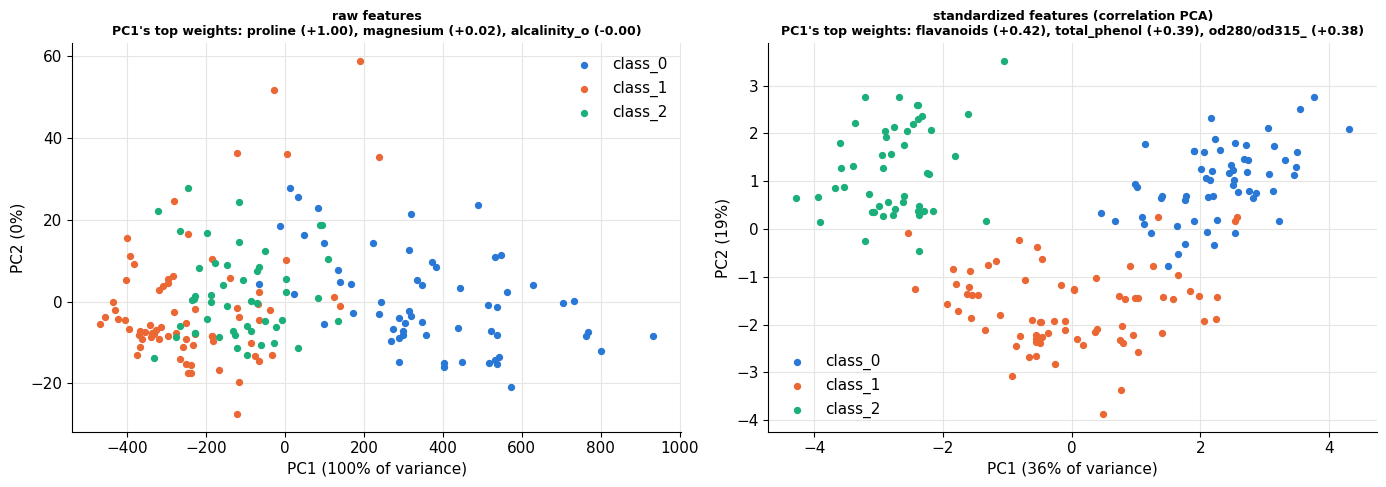

In [9]:
wine = load_wine(); Xw, yw = wine.data, wine.target
print("feature standard deviations:", {f: round(float(v), 2) for f, v in zip(wine.feature_names, Xw.std(0))})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (Xin, nm) in zip(axes, [(Xw, "raw features"), ((Xw - Xw.mean(0)) / Xw.std(0), "standardized features (correlation PCA)")]):
    p = PCA(2).fit(Xin); Z = p.transform(Xin)
    for c_, col in zip(range(3), [C["blue"], C["orange"], C["aqua"]]):
        ax.scatter(*Z[yw == c_].T, s=18, color=col, label=wine.target_names[c_])
    top = np.argsort(-np.abs(p.components_[0]))[:3]
    ax.set(xlabel=f"PC1 ({p.explained_variance_ratio_[0]:.0%} of variance)", ylabel=f"PC2 ({p.explained_variance_ratio_[1]:.0%})",
           title=f"{nm}\nPC1's top weights: " + ", ".join(f"{wine.feature_names[j][:12]} ({p.components_[0, j]:+.2f})" for j in top))
    ax.legend(); ax.title.set_fontsize(9)
fig.tight_layout(); plt.show()

On raw features, PC1 is **proline and nothing else** (weight ≈ 1.00) with 99.8% of the "variance": PCA has simply found the feature with the biggest numbers. After standardizing each feature to unit variance (equivalent to PCA on the *correlation* matrix), every feature gets an equal say, PC1 mixes many chemicals, and the three cultivars separate clearly in the first two components, even though PCA never saw the labels.

Rule of thumb: standardize when features are in different units; don't when they share units and their variances are meaningful (pixel intensities, or returns of similar assets).

**Differencing** is the time-series version of preprocessing (ISYE W3); section 11 shows why it matters.

---
## 7. Visualization: 64-dimensional digits on a page

Project the digits onto their first two principal components and color by the (unused) labels:

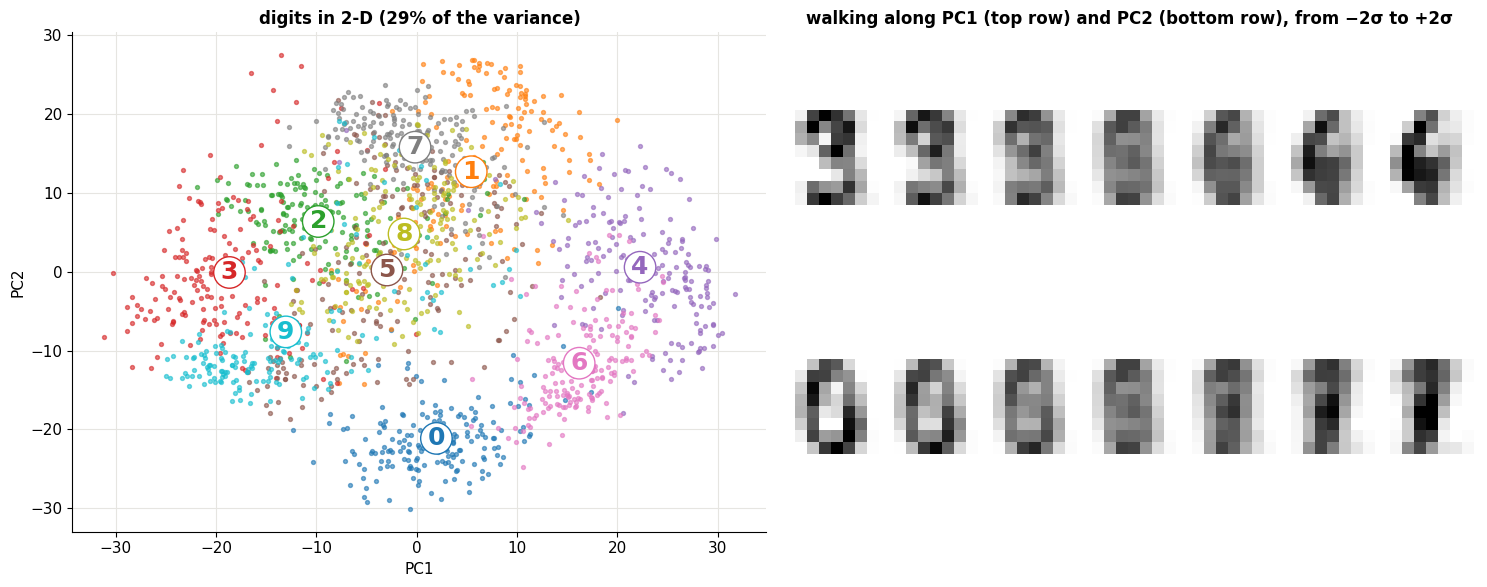

In [10]:
p2 = PCA(2).fit(Xd); Z2 = p2.transform(Xd)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cm = plt.get_cmap("tab10")
for d in range(10):
    axes[0].scatter(*Z2[yd == d].T, s=8, color=cm(d), alpha=0.6)
    axes[0].annotate(str(d), Z2[yd == d].mean(0), fontsize=18, weight="bold", color=cm(d), ha="center", va="center",
                     bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec=cm(d)))
axes[0].set(xlabel="PC1", ylabel="PC2", title=f"digits in 2-D ({p2.explained_variance_ratio_.sum():.0%} of the variance)")
# what moving along each axis means: show images along PC1 and PC2
for row, comp in enumerate([0, 1]):
    for j, t in enumerate(np.linspace(-2.2, 2.2, 7)):
        z = np.zeros(2); z[comp] = t * np.sqrt(p2.explained_variance_[comp])
        img = p2.inverse_transform(z[None])[0].reshape(8, 8)
        ins = axes[1].inset_axes([j / 7, 0.55 - row * 0.5, 1 / 7.3, 0.4]); ins.imshow(img, cmap="gray_r", vmin=0, vmax=16); ins.axis("off")
axes[1].axis("off"); axes[1].set_title("walking along PC1 (top row) and PC2 (bottom row), from −2σ to +2σ")
fig.tight_layout(); plt.show()

With just two of 64 numbers per image, several digits already form their own regions (0, 4, 6, 3), while others pile up in the middle. The right panel shows what the axes *mean*: walking along PC1 morphs a 3-like shape into a 6/4-like one (matching the scatter, where 3s sit on the left and 4s and 6s on the right); walking along PC2 goes from a round 0 to a thin vertical 1. Each principal direction is an image-shaped **pattern** of pixels, and every digit is approximately the mean image plus a weighted sum of these patterns.

---
## 8. Compression and reconstruction

Keeping $k$ components stores $k$ numbers per image (plus the shared mean and $k$ directions) instead of 64. Reconstruction is $\hat x = \mu + U_kU_k^\top(x - \mu)$. 🎚️ **Change $k$:**

In [11]:
pick = [0, 11, 22, 33, 44, 55, 66, 77, 88, 99]
full = MyPCA(64).fit(Xd)
def reconstruct(k=5):
    p = MyPCA(k).fit(Xd); R = p.inverse_transform(p.transform(Xd))
    mse = np.mean((R - Xd) ** 2)
    fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
    for j, i in enumerate(pick):
        axes[0, j].imshow(Xd[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); axes[0, j].axis("off")
        axes[1, j].imshow(R[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); axes[1, j].axis("off")
    axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title(f"k = {k}", loc="left")
    fig.suptitle(f"{k} numbers per image instead of 64: {np.cumsum(full.var_)[k - 1] / full.var_.sum():.0%} of the variance kept, mean squared error {mse:.2f}", y=1.02)
    plt.show()

interact(reconstruct, k=IntSlider(value=5, min=1, max=40, description="k"));

With $k = 1$ every image is the mean digit plus some amount of one pattern, so they all look alike. By $k \approx 10$ most digits are readable; by $k \approx 25$ the reconstructions are close to the originals. The squared reconstruction error is exactly the sum of the discarded eigenvalues (times $m$), which is the "minimum reconstruction error" view again: **no other $k$-dimensional linear subspace reconstructs the data with smaller squared error.**

---
## 9. Eigenfaces

The most famous PCA application (Sirovich & Kirby 1987; Turk & Pentland 1991; ISYE W3, CX lecture 18, HW2 Q4). Treat each face photo as one long vector of pixels and run PCA. The principal directions, reshaped to images, look like ghostly faces: **eigenfaces**. We use 100 small (25 × 25) face crops from the Labeled Faces in the Wild dataset, bundled with scikit-image (it also includes 100 non-face patches, which we'll use in a moment).

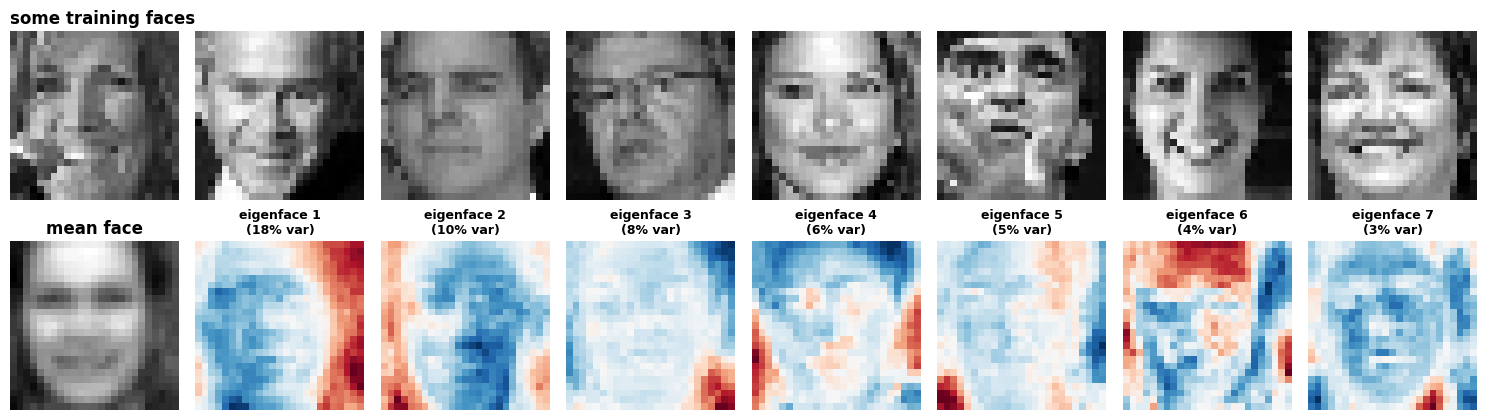

In [12]:
lfw = skdata.lfw_subset()                                      # 200 images: first 100 faces, then 100 non-faces
faces, nonfaces = lfw[:100].reshape(100, -1), lfw[100:].reshape(100, -1)
def normalize(V):                                              # remove brightness and contrast differences
    V = V - V.mean(1, keepdims=True); return V / np.linalg.norm(V, axis=1, keepdims=True)
F, N = normalize(faces), normalize(nonfaces)
r_ = np.random.default_rng(0); idx = r_.permutation(100); F_tr, F_te = F[idx[:70]], F[idx[70:]]
face_pca = MyPCA(40).fit(F_tr)

fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for j in range(8):
    axes[0, j].imshow(faces[idx[j]].reshape(25, 25), cmap="gray"); axes[0, j].axis("off")
axes[0, 0].set_title("some training faces", loc="left")
axes[1, 0].imshow(face_pca.mean_.reshape(25, 25), cmap="gray"); axes[1, 0].set_title("mean face"); axes[1, 0].axis("off")
for j in range(1, 8):
    axes[1, j].imshow(face_pca.U_[:, j - 1].reshape(25, 25), cmap="RdBu_r"); axes[1, j].axis("off")
    axes[1, j].set_title(f"eigenface {j}\n({face_pca.var_[j - 1] / face_pca.var_.sum():.0%} var)", fontsize=9)
fig.tight_layout(); plt.show()

The mean face is a blurred average. The eigenfaces (red = brighter than average, blue = darker) capture the main ways faces differ in this collection: lighting from the left versus the right, overall face shape and size, eyes and brow region, the background. Early eigenfaces are often about **lighting and pose**, not identity, which is a known weakness of eigenface recognition.

🎚️ **Rebuild a held-out face** (one PCA never saw) from more and more eigenfaces:

In [13]:
def face_from_eigenfaces(k=10, which=0):
    x = F_te[which]; p = MyPCA(k).fit(F_tr); z = p.transform(x[None]); xh = p.inverse_transform(z)[0]
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
    axes[0].imshow(x.reshape(25, 25), cmap="gray"); axes[0].set_title("held-out face"); axes[0].axis("off")
    axes[1].imshow(xh.reshape(25, 25), cmap="gray"); axes[1].set_title(f"mean + {k} eigenfaces"); axes[1].axis("off")
    axes[2].bar(range(1, k + 1), z[0], color=C["violet"]); axes[2].set(xlabel="eigenface", ylabel="weight (score)", title=f"the face as {k} numbers")
    fig.tight_layout(); plt.show()

interact(face_from_eigenfaces, k=IntSlider(value=10, min=1, max=60, description="k"), which=IntSlider(value=0, min=0, max=29, description="face #"));

With 70 training faces there are at most 69 eigenfaces, and a new face is never reproduced perfectly: whatever is unique to that person and wasn't in the training set lies outside "face space".

### Distance from face space

That last observation is useful. HW2 Q4 scores a test image by its **projection residual**: the squared distance between the image and its reconstruction from the eigenfaces, $s = \|(x - \mu) - U_kU_k^\top(x - \mu)\|^2$. If $x$ is a face, the eigenfaces should explain it well (small residual); if it's not, they shouldn't. Turk and Pentland used exactly this to **detect** faces. Let's test it on the 30 held-out faces and the 100 non-face patches:

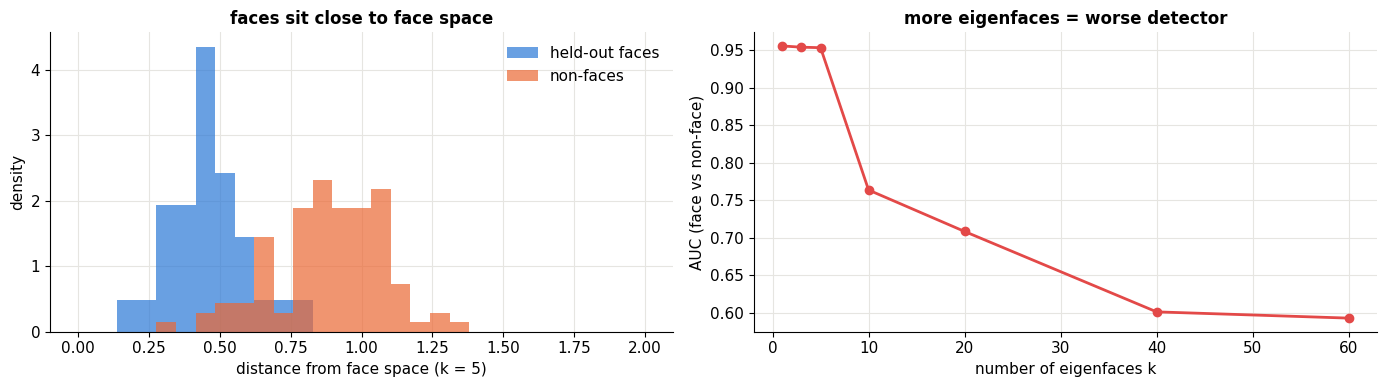

,k,face_residual,nonface_residual,AUC
0,1,0.642,1.294,0.956
1,3,0.536,1.107,0.954
2,5,0.454,0.882,0.954
3,10,0.408,0.575,0.764
4,20,0.350,0.460,0.708
5,40,0.298,0.352,0.601
6,60,0.268,0.312,0.593


In [14]:
from sklearn.metrics import roc_auc_score
def residual(V, p): R = V - p.mean_; return ((R - (R @ p.Uk_) @ p.Uk_.T) ** 2).sum(1)
rows = []
for k in [1, 3, 5, 10, 20, 40, 60]:
    p = MyPCA(k).fit(F_tr); a, b = residual(F_te, p), residual(N, p)
    rows.append(dict(k=k, face_residual=a.mean(), nonface_residual=b.mean(), AUC=roc_auc_score(np.r_[np.zeros(30), np.ones(100)], np.r_[a, b])))
det = pd.DataFrame(rows)
p5 = MyPCA(5).fit(F_tr)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(0, 2, 30)
axes[0].hist(residual(F_te, p5), bins=bins, alpha=0.7, color=C["blue"], label="held-out faces", density=True)
axes[0].hist(residual(N, p5), bins=bins, alpha=0.7, color=C["orange"], label="non-faces", density=True)
axes[0].set(xlabel="distance from face space (k = 5)", ylabel="density", title="faces sit close to face space"); axes[0].legend()
axes[1].plot(det.k, det.AUC, "o-", color=C["red"]); axes[1].set(xlabel="number of eigenfaces k", ylabel="AUC (face vs non-face)", title="more eigenfaces = worse detector")
fig.tight_layout(); plt.show()
det.round(3)

With a handful of eigenfaces, the residual separates faces from non-faces well (AUC ≈ 0.95: a random face beats a random non-face 95% of the time). The surprise is the right panel: **adding eigenfaces makes the detector worse**. With 40 or 60 directions, face space is big enough to approximate almost any 25 × 25 patch, so non-faces fit nearly as well as faces. A detector needs a subspace that's specific, and specificity means few dimensions. (The same logic, model the normal data and flag what it can't explain, is the basis of reconstruction-based anomaly detection in notebook 18.)

> 🤔 **Question: Would this make a good face *recognizer* (who is it?), and how could it be improved?** (HW2 Q4c)
>
> HW2's version builds one eigenface subspace per person and assigns a test image to the person with the smallest residual. It works on tightly controlled photos (same lighting, frontal pose, aligned eyes) and breaks quickly otherwise, because the top eigenfaces encode lighting and pose more than identity. Improvements, roughly in historical order: align and normalize the images; drop the first few (lighting) components; use **Fisherfaces** (LDA, which maximizes *between-person* relative to *within-person* variation instead of total variation; section 13); and today, use deep networks trained to map faces to embeddings where the same person's photos are close together (the contrastive learning of notebook 24).

---
## 10. Denoising

If the signal lives in a low-dimensional subspace and the noise is spread equally over all directions, projecting onto the top components keeps most of the signal and discards most of the noise (CX lecture 18: *"discard the smallest variance features = the noise components, hopefully!"*). 🎚️ **Add noise and choose $k$:**

In [15]:
Xtr_d, Xte_d = Xd[:1400], Xd[1400:]
def denoise(noise=4.0, k=12):
    r = np.random.default_rng(1); noisy = Xte_d + r.normal(0, noise, Xte_d.shape)
    p = MyPCA(k).fit(Xtr_d + np.random.default_rng(2).normal(0, noise, Xtr_d.shape))   # fit on noisy training data too
    clean = p.inverse_transform(p.transform(noisy))
    fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
    for j in range(10):
        for row, Ximg in enumerate([Xte_d, noisy, clean]):
            axes[row, j].imshow(Ximg[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); axes[row, j].axis("off")
    for row, nm in enumerate(["clean", "noisy", f"PCA, k = {k}"]): axes[row, 0].set_title(nm, loc="left", fontsize=10)
    e_noisy, e_clean = np.mean((noisy - Xte_d) ** 2), np.mean((clean - Xte_d) ** 2)
    fig.suptitle(f"error vs. the clean images: noisy {e_noisy:.1f} → denoised {e_clean:.1f}", y=1.0); plt.show()

interact(denoise, noise=FloatSlider(value=4.0, min=0.5, max=8.0, step=0.5, description="noise σ"), k=IntSlider(value=12, min=1, max=64, description="k"));

With strong noise, a moderate $k$ roughly halves the error (and the denoised digits are easier to read, though blurrier). Too small a $k$ throws away signal (every digit drifts toward the mean); $k = 64$ keeps everything, noise included, so there's no denoising at all. The best $k$ shrinks as the noise grows: weaker components get buried first.

---
## 11. PCA on time series: level, slope, curvature

ISYE's finance example: **yield curves**, the interest rate a government pays for borrowing over different horizons (1 month to 30 years), recorded daily. Rates at different maturities move together, so PCA on daily *changes* typically finds three components: **level** (all rates move together), **slope** (short and long rates move oppositely), and **curvature** (the middle moves against the ends). Real yield data needs a download, so we simulate from that classic three-factor structure (Nelson–Siegel shapes) and see whether PCA can find the factors without being told:

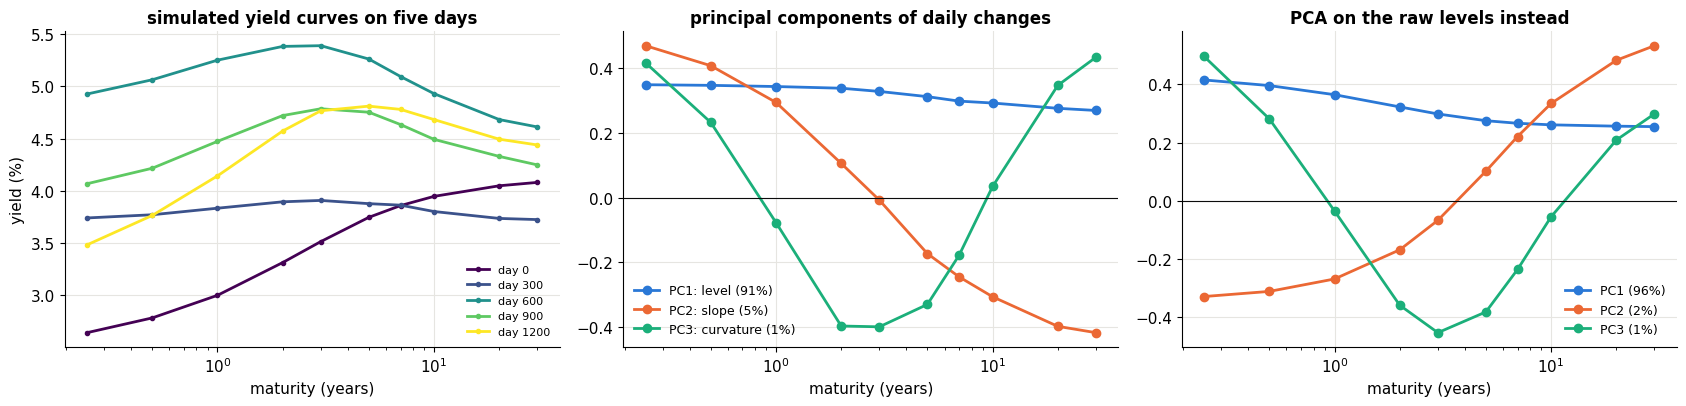

In [16]:
mats = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
lam = 0.6
load_level = np.ones_like(mats)
load_slope = (1 - np.exp(-lam * mats)) / (lam * mats)
load_curve = load_slope - np.exp(-lam * mats)
T = 1500; r_ = np.random.default_rng(3)
f = np.cumsum(r_.normal(0, [0.06, 0.05, 0.08], size=(T, 3)), axis=0) + [4.0, -1.5, 0.5]   # factors wander like random walks
yields = f[:, :1] * load_level + f[:, 1:2] * load_slope + f[:, 2:3] * load_curve + r_.normal(0, 0.01, (T, len(mats)))

d_y = np.diff(yields, axis=0)                                   # daily changes: first-order differencing
p_diff = PCA(3).fit(d_y)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for c_, col in zip(range(0, T, 300), plt.cm.viridis(np.linspace(0, 1, 5))):
    axes[0].plot(mats, yields[c_], "o-", ms=3, color=col, label=f"day {c_}")
axes[0].set(xscale="log", xlabel="maturity (years)", ylabel="yield (%)", title="simulated yield curves on five days"); axes[0].legend(fontsize=8)
for k, (col, nm) in enumerate(zip([C["blue"], C["orange"], C["aqua"]], ["PC1: level", "PC2: slope", "PC3: curvature"])):
    v = p_diff.components_[k] * np.sign(p_diff.components_[k][-1] if k == 0 else p_diff.components_[k][0])
    axes[1].plot(mats, v, "o-", color=col, label=f"{nm} ({p_diff.explained_variance_ratio_[k]:.0%})")
axes[1].axhline(0, color=C["ink"], lw=0.8); axes[1].set(xscale="log", xlabel="maturity (years)", title="principal components of daily changes"); axes[1].legend(fontsize=9)
p_lvl = PCA(3).fit(yields)
for k, col in zip(range(3), [C["blue"], C["orange"], C["aqua"]]):
    axes[2].plot(mats, p_lvl.components_[k], "o-", color=col, label=f"PC{k + 1} ({p_lvl.explained_variance_ratio_[k]:.0%})")
axes[2].axhline(0, color=C["ink"], lw=0.8); axes[2].set(xscale="log", xlabel="maturity (years)", title="PCA on the raw levels instead"); axes[2].legend(fontsize=9)
fig.tight_layout(); plt.show()

On daily changes (middle), PCA recovers the three textbook shapes: a flat line (level), a monotone curve crossing zero (slope), and a hump (curvature), with level explaining most of the movement. On the raw levels (right), PCA happens to find similar shapes here, because in this simulation nothing but the three factors moves the curves. But the variance shares are different (level now claims 96%), and they mostly reflect how far each factor happened to **drift** over this particular sample, since the levels are random walks. In real data, where unrelated series trend for unrelated reasons, PCA on levels picks up those shared drifts as if they were real structure.

Why does differencing matter? Two completely **independent** random walks look strongly correlated over any finite stretch, because both drift. PCA (which only sees covariances) can't tell shared drift from a real relationship:

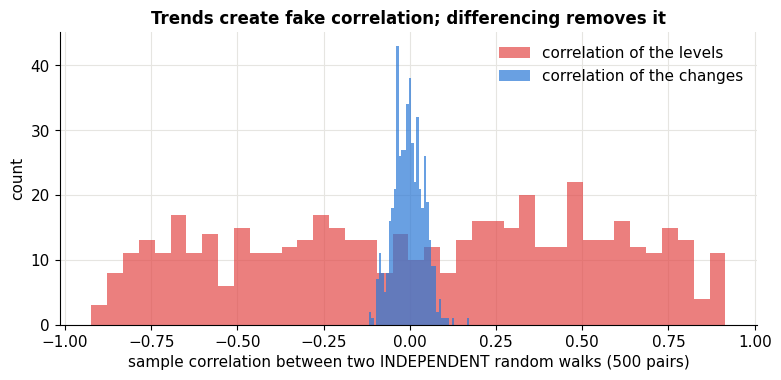

typical |correlation|: levels 0.43, changes 0.032


In [17]:
r_ = np.random.default_rng(7)
corrs_lvl, corrs_diff = [], []
for _ in range(500):
    a, b = np.cumsum(r_.normal(size=(2, 500)), axis=1)          # two unrelated random walks
    corrs_lvl.append(np.corrcoef(a, b)[0, 1]); corrs_diff.append(np.corrcoef(np.diff(a), np.diff(b))[0, 1])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(corrs_lvl, bins=40, alpha=0.7, color=C["red"], label="correlation of the levels")
ax.hist(corrs_diff, bins=40, alpha=0.7, color=C["blue"], label="correlation of the changes")
ax.set(xlabel="sample correlation between two INDEPENDENT random walks (500 pairs)", ylabel="count", title="Trends create fake correlation; differencing removes it"); ax.legend()
plt.show()
print(f"typical |correlation|: levels {np.median(np.abs(corrs_lvl)):.2f}, changes {np.median(np.abs(corrs_diff)):.3f}")

Levels of unrelated walks routinely show correlations of ±0.5 or more ("spurious correlation"); their daily changes show essentially none. That's why ISYE recommends first-order differencing, $y_t = x_t - x_{t-1}$, before PCA on time series.

---
## 12. Probabilistic PCA

CX 4240 (lecture 18) presents PCA a third way: as a **latent-variable model**, following the same pipeline as GMMs in notebook 15.

1. **Model.** Each observation comes from a hidden low-dimensional vector: $z \sim \mathcal{N}(0, I_k)$, then $x = Wz + \mu + \varepsilon$ with noise $\varepsilon \sim \mathcal{N}(0, \sigma^2 I_n)$. Here $W$ is $n \times k$. It's like a GMM with a **continuous** hidden variable instead of a discrete label.
2. **Loss.** The marginal $p(x)$ is Gaussian: $x \sim \mathcal{N}(\mu,\, WW^\top + \sigma^2 I)$. Maximize its log-likelihood.
3. **Optimizer.** Here the necessary conditions can be solved in closed form (Tipping & Bishop, 1999). With $\Sigma = U\Lambda U^\top$ the sample covariance:

$$\sigma^2_{\text{ML}} = \frac{1}{n-k}\sum_{j=k+1}^{n}\lambda_j, \qquad W_{\text{ML}} = U_k\big(\Lambda_k - \sigma^2_{\text{ML}} I\big)^{1/2},$$

up to a rotation. The noise variance is the **average discarded eigenvalue**, and $W$ spans exactly the top-$k$ principal subspace: classical PCA falls out as the maximum-likelihood solution. (CX's version derives it through the ELBO, the same bound as EM; the posterior over $z$ given $x$ is Gaussian with a mean that projects $x$ onto the subspace.)

Let's compute it, check it against scikit-learn (whose `PCA` reports exactly this σ² as `noise_variance_` and the PPCA log-likelihood as `score`), and then use the model generatively:

σ² (avg discarded eigenvalue): ours 2.8878, scikit-learn noise_variance_ 2.8878
average log-likelihood:        ours -150.1684, scikit-learn score         -150.1684


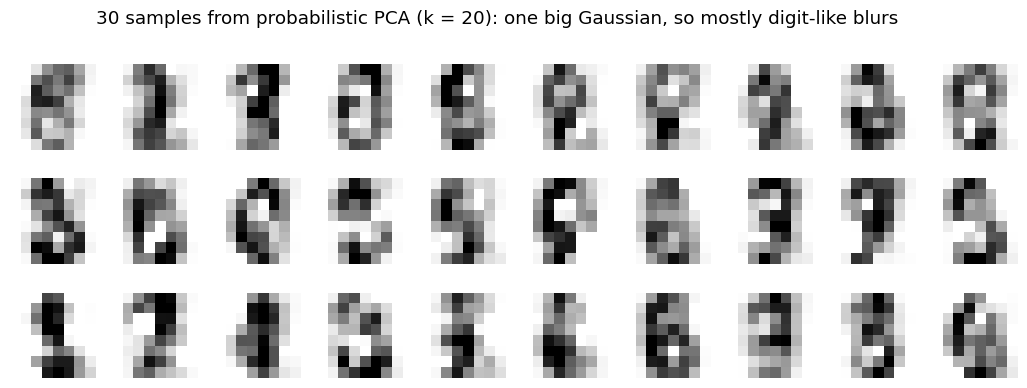

In [18]:
k = 20
pp = MyPCA(k).fit(Xd)
lam_all = pp.var_ * len(Xd) / (len(Xd) - 1)                     # match sklearn's unbiased covariance
sigma2 = lam_all[k:].mean()
W = pp.U_[:, :k] * np.sqrt(lam_all[:k] - sigma2)
Cov = W @ W.T + sigma2 * np.eye(64)
from scipy.stats import multivariate_normal
ll_ours = multivariate_normal(pp.mean_, Cov, allow_singular=True).logpdf(Xd).mean()
skp = PCA(k).fit(Xd)
print(f"σ² (avg discarded eigenvalue): ours {sigma2:.4f}, scikit-learn noise_variance_ {skp.noise_variance_:.4f}")
print(f"average log-likelihood:        ours {ll_ours:.4f}, scikit-learn score         {skp.score(Xd):.4f}")

# Generate new digits: z ~ N(0, I), x = W z + μ (+ noise)
zs = np.random.default_rng(0).normal(size=(30, k))
gen = zs @ W.T + pp.mean_
fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
for ax, img in zip(axes.ravel(), gen):
    ax.imshow(np.clip(img, 0, 16).reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); ax.axis("off")
fig.suptitle("30 samples from probabilistic PCA (k = 20): one big Gaussian, so mostly digit-like blurs", y=1.0); plt.show()

Our closed form matches scikit-learn's numbers exactly. The samples are digit-*ish* but blurry and often ambiguous: PPCA is a single Gaussian, and the set of all digits is not one Gaussian blob. Compare the GMM samples in notebook 15 (many Gaussians, sharper). The **VAE** (notebook 23) keeps PPCA's structure ($z \sim \mathcal{N}(0, I)$, $x$ generated from $z$) but replaces the linear map $Wz + \mu$ with a neural network, and fits it with the ELBO.

> 🤔 **Question: Why bother with a probabilistic version if it gives the same subspace?**
>
> Because a probability model can do things a projection can't: assign a **likelihood** to new data (for model selection, or to flag anomalies), handle **missing values** with EM, combine into mixtures of PCAs, and **generate** samples. And it makes PCA one instance of the general pipeline (model → likelihood → optimizer), which is what lets you replace its pieces with neural networks.

---
## 13. What PCA can't do

**Only linear structure.** PCA finds flat subspaces. Data on a curved surface (a "manifold") can't be flattened by any projection. On concentric circles, no direction separates the rings. **Kernel PCA** runs PCA after an implicit nonlinear feature map (the kernel trick from notebook 11). With a degree-2 polynomial kernel the map is $(x_1^2, \sqrt2x_1x_2, x_2^2)$, and in that space the squared radius $x_1^2 + x_2^2$ is just a linear direction:

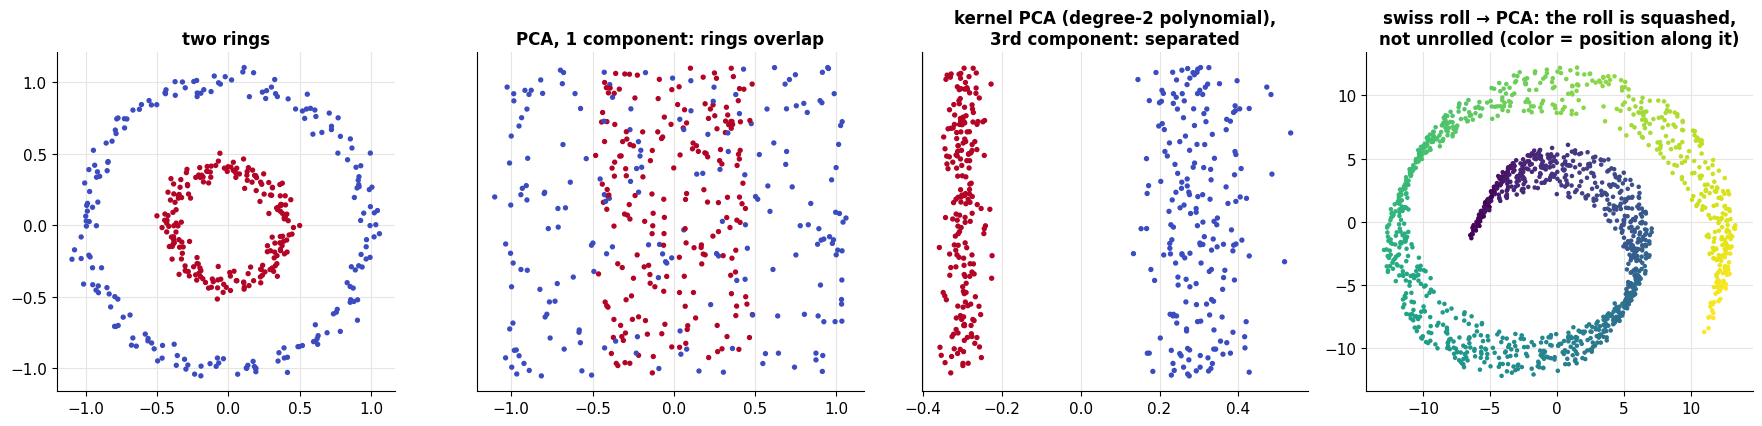

In [19]:
Xc_, yc_ = make_circles(400, factor=0.4, noise=0.05, random_state=0)
Xr, tr_ = make_swiss_roll(1500, noise=0.1, random_state=0)
fig = plt.figure(figsize=(18, 4.4))
ax = fig.add_subplot(1, 4, 1); ax.scatter(*Xc_.T, c=yc_, cmap="coolwarm", s=8); ax.set(aspect="equal", title="two rings")
Zl = PCA(1).fit_transform(Xc_)
ax = fig.add_subplot(1, 4, 2); ax.scatter(Zl[:, 0], np.random.default_rng(0).uniform(-1, 1, 400), c=yc_, cmap="coolwarm", s=8); ax.set(yticks=[], title="PCA, 1 component: rings overlap")
Zk = KernelPCA(3, kernel="poly", degree=2, gamma=1, coef0=0).fit_transform(Xc_)
ax = fig.add_subplot(1, 4, 3); ax.scatter(Zk[:, 2], np.random.default_rng(0).uniform(-1, 1, 400), c=yc_, cmap="coolwarm", s=8); ax.set(yticks=[], title="kernel PCA (degree-2 polynomial),\n3rd component: separated")
Zr = PCA(2).fit_transform(Xr)
ax = fig.add_subplot(1, 4, 4); ax.scatter(*Zr.T, c=tr_, cmap="viridis", s=5); ax.set(title="swiss roll → PCA: the roll is squashed,\nnot unrolled (color = position along it)")
fig.tight_layout(); plt.show()

In the lifted space the first two components still describe position around the rings (the outer ring dominates the variance), but the **third** is essentially the squared radius, and it separates the rings perfectly. Notice that "most variance" and "most useful" are again different things (more on that below). Nonlinear methods for visualization (t-SNE, UMAP) and learned nonlinear encoders (autoencoders, notebook 23) exist precisely for curved data. For the swiss roll, PCA just looks at it from the side: points far apart along the roll (different colors) land on top of each other.

**Unsupervised: high variance isn't the same as useful.** PCA keeps the directions where the data varies most, ignoring any labels. If the label-relevant direction has small variance, PCA throws it away first. A classifier-aware alternative is **LDA** (notebook 09), which maximizes between-class separation relative to within-class spread:

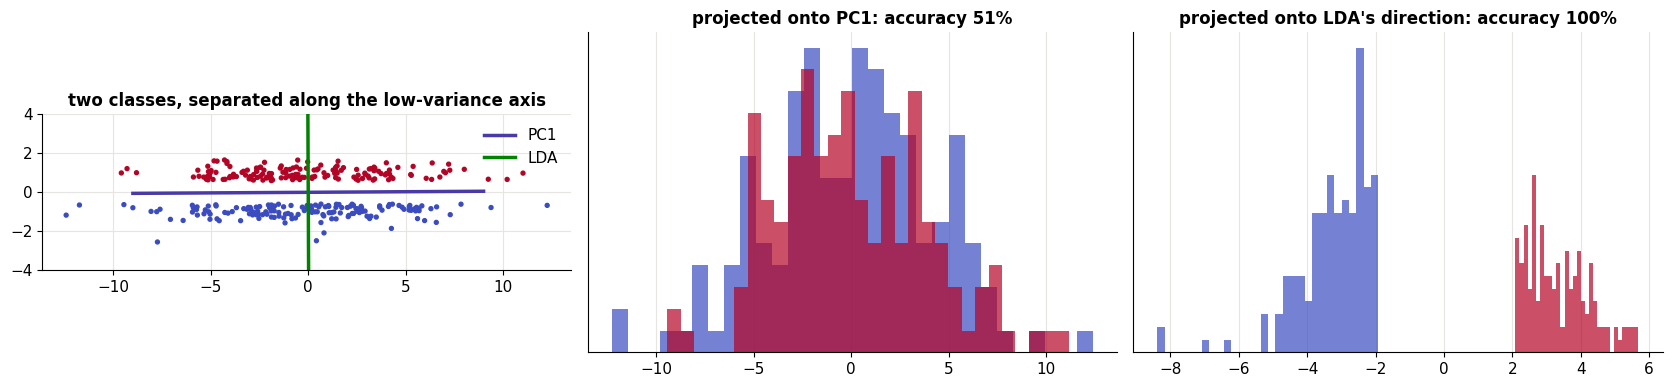

In [20]:
r_ = np.random.default_rng(0)
n_ = 300
Xs2 = np.column_stack([r_.normal(0, 4, n_), r_.normal(0, 0.5, n_)])   # big spread along x
ys2 = (Xs2[:, 1] > 0).astype(int); Xs2[:, 1] += np.where(ys2 == 1, 0.6, -0.6)   # but the classes differ along y
pc1 = PCA(1).fit(Xs2); lda = LinearDiscriminantAnalysis(n_components=1).fit(Xs2, ys2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(*Xs2.T, c=ys2, cmap="coolwarm", s=8)
for v, col, nm in [(pc1.components_[0], C["violet"], "PC1"), (lda.scalings_[:, 0] / np.linalg.norm(lda.scalings_[:, 0]), C["green"], "LDA")]:
    axes[0].plot(*np.c_[-9 * v, 9 * v], color=col, lw=2.5, label=nm)
axes[0].set(aspect="equal", ylim=(-4, 4), title="two classes, separated along the low-variance axis"); axes[0].legend()
for ax, Z, nm in [(axes[1], pc1.transform(Xs2)[:, 0], "projected onto PC1"), (axes[2], lda.transform(Xs2)[:, 0], "projected onto LDA's direction")]:
    acc = cross_val_score(LogisticRegression(), Z[:, None], ys2, cv=5).mean()
    ax.hist(Z[ys2 == 0], bins=30, alpha=0.7, color=plt.cm.coolwarm(0.0)); ax.hist(Z[ys2 == 1], bins=30, alpha=0.7, color=plt.cm.coolwarm(1.0))
    ax.set(title=f"{nm}: accuracy {acc:.0%}", yticks=[])
fig.tight_layout(); plt.show()

PC1 points along the long axis, where the two classes overlap completely (≈50% accuracy, a coin flip). LDA's direction is nearly vertical and separates them almost perfectly. So when you use PCA as preprocessing for a classifier, check that the discarded components didn't carry the signal (for instance, by cross-validating the number of components as part of the pipeline).

---
## 14. Summary

| View | PCA finds the $k$-dimensional subspace that… | Comes from |
|---|---|---|
| Max variance | keeps the most variance of the projected data | ISYE W3, sections 2–4 |
| Min reconstruction error | reconstructs the data with the smallest squared error | section 2 (Pythagoras), section 8 |
| Probabilistic | maximizes the likelihood of a linear-Gaussian latent model | CX lecture 18, section 12 |

**Recipe:** center (and usually standardize) → SVD of the data matrix → keep the top $k$ right singular vectors → scores $z = U_k^\top(x - \mu)$, reconstruction $\hat x = \mu + U_kz$. Choose $k$ from the scree plot, a variance target (say 90%), or the downstream task's validation score.

**Uses:** visualization, compression, denoising, decorrelating features, fixing multicollinearity (principal component regression), anomaly scores from reconstruction residuals, and the eigen-patterns themselves (eigenfaces, yield-curve factors) as interpretable summaries. **Limits:** linear only; sensitive to scaling and outliers; ignores labels.

Next: **recommender systems** (notebook 17) apply the same low-rank idea to a matrix with most of its entries **missing**: who will like which movie?

### ✏️ Exercises

1. HW2 Q1: prove that the second principal direction is the eigenvector with the second-largest eigenvalue. (Use two Lagrange multipliers, and show the one for $u^\top u_1 = 0$ must be zero.)
2. HW2 Q2: compute the $3\times3$ covariance matrix of the five students' grades in linear algebra, calculus, and ISYE 4600 (rows 86 94 93 99 89 / 95 84 96 96 89 / 84 87 82 90 86). Which pair of courses is most correlated? Find its principal components.
3. For the bedrooms/bathrooms example with $x_1 = 1.5x_2$, find the eigenvectors of the $2\times2$ feature covariance analytically and show that PC1 is $\frac{1}{\sqrt{13}}(3, 2)$ and PC2 has eigenvalue 0.
4. Show that the mean squared reconstruction error with $k$ components equals $\sum_{j>k}\lambda_j$. Verify it numerically on the digits.
5. Implement **principal component regression** on notebook 05's diabetes data: regress on the top $k$ components and choose $k$ by cross-validation. Compare with ridge regression.
6. Run the face-space detector on the *raw* (unnormalized) images. Why does it get much worse? What does normalization remove?
7. Fit PCA to the wine data with and without standardizing, then train a logistic regression on the top two components of each. Which gives better cross-validated accuracy, and why?

### References

- ISYE 4600 W3 (Principal Component Analysis) and HW2 Q1–Q4.
- CX 4240 lecture 18 (dimension reduction, probabilistic PCA as a Gaussian latent-variable model, eigenfaces).
- K. Pearson, *On lines and planes of closest fit to systems of points in space* (1901); H. Hotelling, *Analysis of a complex of statistical variables into principal components* (1933).
- L. Sirovich & M. Kirby, *Low-dimensional procedure for the characterization of human faces* (1987); M. Turk & A. Pentland, *Eigenfaces for Recognition*, J. Cognitive Neuroscience (1991).
- M. Tipping & C. Bishop, *Probabilistic Principal Component Analysis*, JRSS-B (1999).
- R. Litterman & J. Scheinkman, *Common Factors Affecting Bond Returns*, J. Fixed Income (1991): level, slope, curvature.
- B. Schölkopf, A. Smola & K.-R. Müller, *Nonlinear Component Analysis as a Kernel Eigenvalue Problem*, Neural Computation (1998).
- C. Bishop, *Pattern Recognition and Machine Learning*, Chapter 12.

**Next → [17 · Recommender Systems](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/17_recommender_systems.ipynb)**